# 03. Fire and smoke classification: baselines, calibration and risk control
Frozen-CLIP baselines are read from `docs/data/fire_frozen_baselines.json`. LoRA/CNN results from `trackb_results.json` are shown if present. The calibration and risk-control demos run live on simulated scores to show how the method behaves, not to report performance.

In [1]:
import json, os, sys, pathlib
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
ROOT = pathlib.Path(os.getcwd()).resolve().parent if pathlib.Path(os.getcwd()).name == "notebooks" else pathlib.Path(os.getcwd())
sys.path.insert(0, str(ROOT / "src"))
J = lambda n: json.load(open(ROOT / "docs" / "data" / n))
COL = {"blue": "#2f6fb3", "orange": "#d9822b", "grey": "#8a8f98", "green": "#3a9a6e", "red": "#c24d4d"}

## Frozen CLIP: zero-shot vs linear probe
AoF is the held-out fixed-camera source.

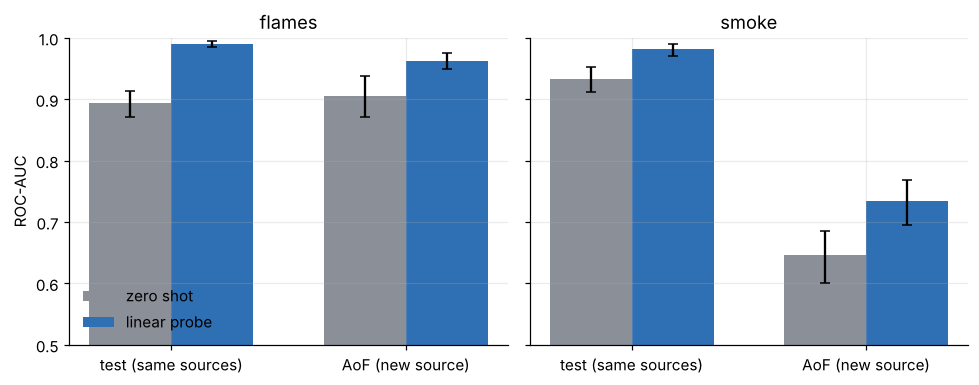

In [2]:
f = J("fire_frozen_baselines.json"); fig, axs = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, h in zip(axs, ("flames", "smoke")):
    for i, (m, c) in enumerate((("zero_shot", COL["grey"]), ("linear_probe", COL["blue"]))):
        v = np.array([f[m][e][h]["roc_auc"] for e in ("test", "xsrc_aof")]); ci = np.array([f[m][e][h]["roc_ci95"] for e in ("test", "xsrc_aof")])
        ax.bar(np.arange(2) + (i - .5) * .35, v, .35, yerr=[v - ci[:, 0], ci[:, 1] - v], capsize=3, color=c, label=m.replace("_", " "))
    ax.set_xticks(range(2), ["test (same sources)", "AoF (new source)"]); ax.set_title(h); ax.set_ylim(.5, 1)
axs[0].set_ylabel("ROC-AUC"); axs[0].legend(frameon=False, loc="lower left"); plt.tight_layout(); plt.show()

**Reading:** smoke detection drops sharply on a new source while flames do not. In-distribution numbers are optimistic.

## LoRA vs CNN baselines (3 seeds), WiSE-FT, calibrated thresholds

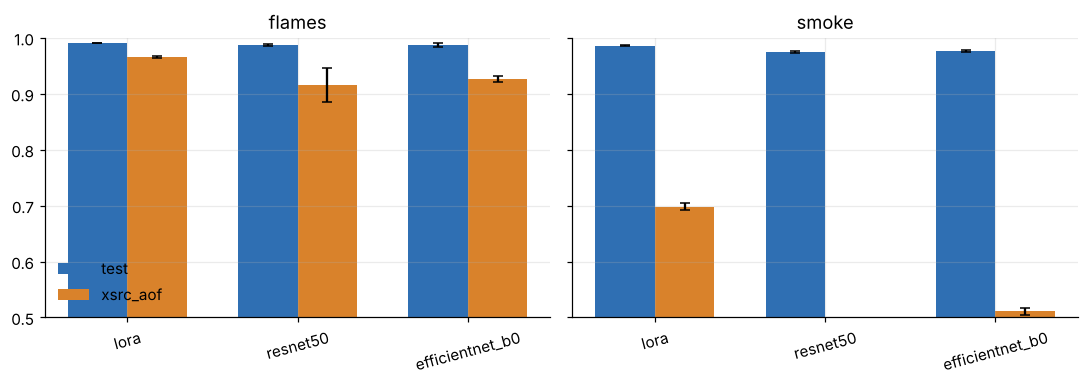

WiSE alpha 0.0 {'val': {'flames': 0.894, 'smoke': 0.808}, 'test': {'flames': 0.907, 'smoke': 0.868}, 'xsrc_aof': {'flames': 0.892, 'smoke': 0.68}}
WiSE alpha 0.25 {'val': {'flames': 0.974, 'smoke': 0.927}, 'test': {'flames': 0.971, 'smoke': 0.952}, 'xsrc_aof': {'flames': 0.915, 'smoke': 0.678}}
WiSE alpha 0.5 {'val': {'flames': 0.988, 'smoke': 0.971}, 'test': {'flames': 0.987, 'smoke': 0.98}, 'xsrc_aof': {'flames': 0.934, 'smoke': 0.666}}
WiSE alpha 0.75 {'val': {'flames': 0.991, 'smoke': 0.981}, 'test': {'flames': 0.991, 'smoke': 0.985}, 'xsrc_aof': {'flames': 0.952, 'smoke': 0.689}}
WiSE alpha 1.0 {'val': {'flames': 0.992, 'smoke': 0.982}, 'test': {'flames': 0.991, 'smoke': 0.986}, 'xsrc_aof': {'flames': 0.965, 'smoke': 0.707}}
{
 "flames": {
  "temperature": 0.7122964572388175,
  "threshold": 0.16801147041813091,
  "target_fnr": 0.05,
  "delta": 0.1,
  "feasible": true,
  "cal_empirical_fnr": 0.036016949152542374,
  "test": {
   "fnr": 0.024539877300613498,
   "recall": 0.9754601226

In [3]:
p = ROOT / "docs/data/trackb_results.json"
if p.exists() and json.load(open(p))["methods"].get("lora", {}).get("test"):
    r = json.load(open(p)); fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
    for ax, h in zip(axs, ("flames", "smoke")):
        names = [n for n in r["methods"] if r["methods"][n].get("test")]
        for i, ev in enumerate(("test", "xsrc_aof")):
            m = [r["methods"][n][ev][h]["roc"][0] for n in names]; s = [r["methods"][n][ev][h]["roc"][1] for n in names]
            ax.bar(np.arange(len(names)) + (i - .5) * .35, m, .35, yerr=s, capsize=3, color=[COL["blue"], COL["orange"]][i], label=ev)
        ax.set_xticks(range(len(names)), names, rotation=15); ax.set_title(h); ax.set_ylim(.5, 1)
    axs[0].legend(frameon=False); plt.tight_layout(); plt.show()
    for a_, v in sorted(r["wise"].items()): print("WiSE alpha", a_, {k: {h: round(v[k][h]["roc"], 3) for h in v[k]} for k in v})
    print(json.dumps(r["risk_control"], indent=1, default=float)[:1800])
else: print("LoRA / CNN results not available yet (run scripts/eval_trackb.py after the Track B jobs finish)")

## Demo: temperature scaling fixes an over-confident head (simulated)

fitted T = 3.09


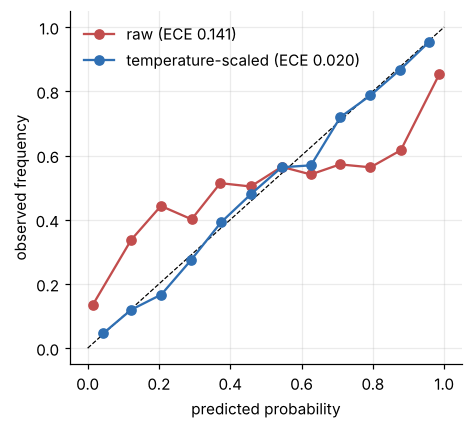

In [4]:
from fire_assessor.calibration import ece, fit_temperature, sigmoid
rng = np.random.default_rng(0); z = rng.normal(size=6000) * 2; y = (rng.random(6000) < sigmoid(z)).astype(int); raw = z * 3   # logits inflated 3x
T = fit_temperature(raw, y); print("fitted T = %.2f" % T)
def rel(p, y, bins=12):
    e = np.linspace(0, 1, bins + 1); i = np.clip(np.digitize(p, e[1:-1]), 0, bins - 1)
    return [(p[i == k].mean(), y[i == k].mean()) for k in range(bins) if (i == k).sum() > 20]
fig, ax = plt.subplots(figsize=(4.4, 4)); ax.plot([0, 1], [0, 1], "k--", lw=.8)
for p, nm, c in ((sigmoid(raw), "raw", COL["red"]), (sigmoid(raw / T), "temperature-scaled", COL["blue"])): q = np.array(rel(p, y)); ax.plot(q[:, 0], q[:, 1], "o-", color=c, label=f"{nm} (ECE {ece(p, y):.3f})")
ax.set_xlabel("predicted probability"); ax.set_ylabel("observed frequency"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

## Demo: risk-controlled threshold keeps false negatives below the target (simulated)
Learn-then-Test: choose the highest threshold whose miss rate is certified <= alpha with probability >= 1 - delta. Over repeated calibration draws, the true miss rate should exceed alpha in at most a fraction delta of draws. This holds only if deployment data is exchangeable with calibration data.

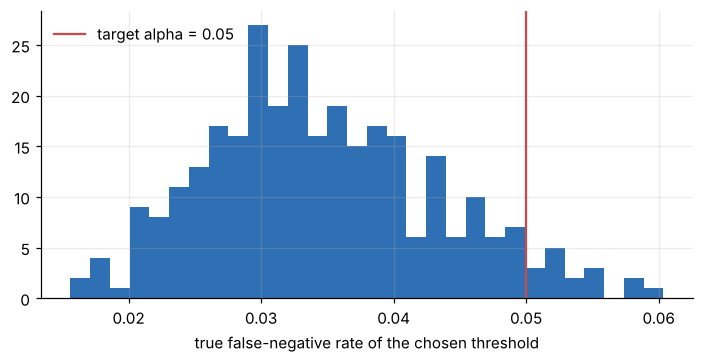

fraction of draws with true FNR > alpha: 0.050 (allowed: delta = 0.10);  mean precision at the operating point 0.48


In [5]:
from fire_assessor.risk_control import select_threshold
alpha, delta, n_cal = .05, .1, 400; rng = np.random.default_rng(1); true_fnr, prec = [], []
neg_s = rng.beta(2, 5, 4000)
for _ in range(300):
    pos = rng.beta(5, 2, n_cal); r = select_threshold(np.r_[pos, neg_s[:1600]], np.r_[np.ones(n_cal), np.zeros(1600)], alpha, delta)
    true_fnr.append(np.mean(rng.beta(5, 2, 20000) < r.threshold)); prec.append(r.precision)
true_fnr = np.array(true_fnr); fig, ax = plt.subplots(figsize=(6.5, 3.4)); ax.hist(true_fnr, bins=30, color=COL["blue"]); ax.axvline(alpha, color=COL["red"], label=f"target alpha = {alpha}")
ax.set_xlabel("true false-negative rate of the chosen threshold"); ax.legend(frameon=False); plt.tight_layout(); plt.show()
print("fraction of draws with true FNR > alpha: %.3f (allowed: delta = %.2f);  mean precision at the operating point %.2f" % ((true_fnr > alpha).mean(), delta, np.mean(prec)))